# Spoken Digit Recognition

Deep learning classification of spoken digits (0 to 9) from short audio recordings, using the Free Spoken Digit Dataset (FSDD) from MathWorks Signal Processing datasets.

## Dataset

The dataset contains **2,000 voice recordings** of the digits 0 to 9, spoken by **four speakers** ([MathWorks](https://www.mathworks.com/help/signal/ug/data-sets-for-signal-processing.html#mw_550b81db-14c1-4c65-84d0-d28574c8616a)). Each digit is represented by 200 recordings, so the classes are perfectly balanced.

| Property | Value |
|---|---|
| Recordings | 2,000 |
| Classes | 10 (digits 0 to 9) |
| Recordings per class | 200 |
| Speakers | 4 |
| Sample rate | 8 kHz |
| Bit depth | 16-bit |
| Channels | 1 (mono) |
| Duration | 0.14 s to 2.28 s (variable) |

Having several speakers introduces variation in accent and vocal characteristics, which makes the dataset suitable for building digit recognition models that generalise across different voices.

## Goal

Train a model that takes a raw audio recording as input and predicts which digit was spoken, and evaluate how well it generalises to unseen speakers.

## Imports and dataset

In [1]:
import warnings
warnings.filterwarnings("ignore")

import os
import random
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Audio
import librosa
import librosa.display
import soundfile as sf
from IPython.display import Audio, display

# PyTorch
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchaudio
import torchaudio.transforms as T

# Splitting and evaluation
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

from tqdm.auto import tqdm

In [2]:
import urllib.request
import zipfile

data_url = "https://ssd.mathworks.com/supportfiles/audio/FSDD.zip"
download_folder = Path("data") / "FSDD"
zip_file = download_folder / "FSDD.zip"

# Check if data set already exists. Otherwise, download it and unzip
if not download_folder.exists():
    download_folder.mkdir(parents=True)
    # Download data set
    urllib.request.urlretrieve(data_url, zip_file)
    with zipfile.ZipFile(zip_file) as zf:
        zf.extractall(download_folder)

print(download_folder.resolve())

/Users/gabrielaslomiany/PyCharmMiscProject/Grey_Matter_Multiplication/Spoken Digit Recognition/data/FSDD


In [3]:
# use gpu if it's available if not cpu which is much slower
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [4]:
DATA_DIR = Path("data/FSDD")

records = []
for path in sorted(DATA_DIR.rglob("*.wav")):
    digit, speaker, _ = path.stem.split("_")
    info = sf.info(path)
    records.append({
        "path": str(path),
        "digit": int(digit),
        "speaker": speaker,
        "sample_rate": info.samplerate,
        "n_samples": info.frames,
        "duration [s]": info.frames / info.samplerate,
    })

df = pd.DataFrame(records)
print(df.shape)
df.head()

(2000, 6)


,path,digit,speaker,sample_rate,n_samples,duration [s]
0,data/FSDD/FSDD/recordings/0_jackson_0.wav,0,jackson,8000,5148,0.643500
1,data/FSDD/FSDD/recordings/0_jackson_1.wav,0,jackson,8000,4261,0.532625
2,data/FSDD/FSDD/recordings/0_jackson_10.wav,0,jackson,8000,5451,0.681375
3,data/FSDD/FSDD/recordings/0_jackson_11.wav,0,jackson,8000,4914,0.614250
4,data/FSDD/FSDD/recordings/0_jackson_12.wav,0,jackson,8000,4087,0.510875


- **`sample_rate`**: how many amplitude measurements are taken per second, in hertz (Hz); FSDD uses 8,000 Hz.
- **`n_samples`**: the total number of amplitude measurements in the recording, i.e. the length of the signal array.
- **`duration`**: how long the recording lasts, in seconds, calculated as $\text{duration} = \dfrac{n_{\text{samples}}}{\text{sample\_rate}}$.

## Data sanity check before EDA

- 200 per digit: each digit 0 to 9 should have exactly 200 recordings, so the classes are balanced. If one digit had far fewer, the model would be biased against it.
- How many per speaker: if one speaker has many more recordings than the others, the model may learn that voice best, and this also matters for speaker-based split.
- All at 8 kHz: every file should have the same sample rate. If one were 16 kHz, its spectrogram would look stretched and not comparable to the others.
- All mono: every file should have one audio channel. A stereo file would have two channels and a different array shape, which would break pipeline.


In [5]:
print(f'Recordings per digit: {df["digit"].value_counts().sort_index()}')

Recordings per digit: digit
0    200
1    200
2    200
3    200
4    200
5    200
6    200
7    200
8    200
9    200
Name: count, dtype: int64


In [6]:
print(f'Recordings per speaker: {df["speaker"].value_counts()}')

Recordings per speaker: speaker
jackson     500
nicolas     500
theo        500
yweweler    500
Name: count, dtype: int64


In [7]:
# digits per speaker
print(pd.crosstab(df["speaker"], df["digit"]))

digit      0   1   2   3   4   5   6   7   8   9
speaker                                         
jackson   50  50  50  50  50  50  50  50  50  50
nicolas   50  50  50  50  50  50  50  50  50  50
theo      50  50  50  50  50  50  50  50  50  50
yweweler  50  50  50  50  50  50  50  50  50  50


In [8]:
# expect [8000]
print(df["sample_rate"].unique())

[8000]


## EDA

### Digit audio display

In [9]:
path = df.loc[df["digit"] == 0, "path"].iloc[0]
print(path)
Audio(path)

data/FSDD/FSDD/recordings/0_jackson_0.wav


In [10]:
y, sr = librosa.load(path, sr=None)
print(y.shape, sr)
Audio(y, rate=sr)

(5148,) 8000


### Waveforms per digit

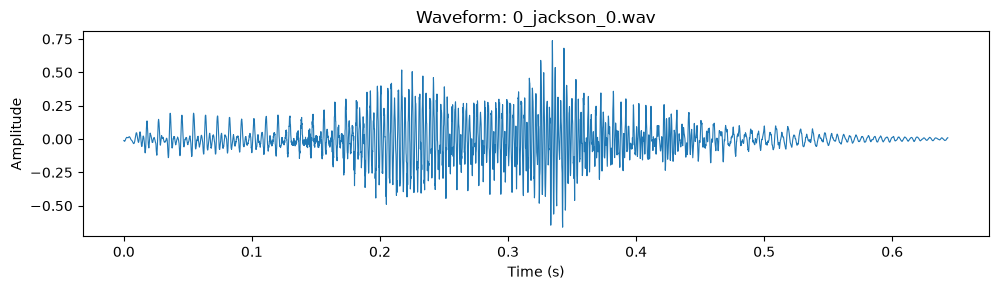

In [11]:
t = np.arange(len(y)) / sr

plt.figure(figsize=(10, 3))
plt.plot(t, y, linewidth=0.8)
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.title(f"Waveform: {path.split('/')[-1]}")
plt.tight_layout()
plt.show()

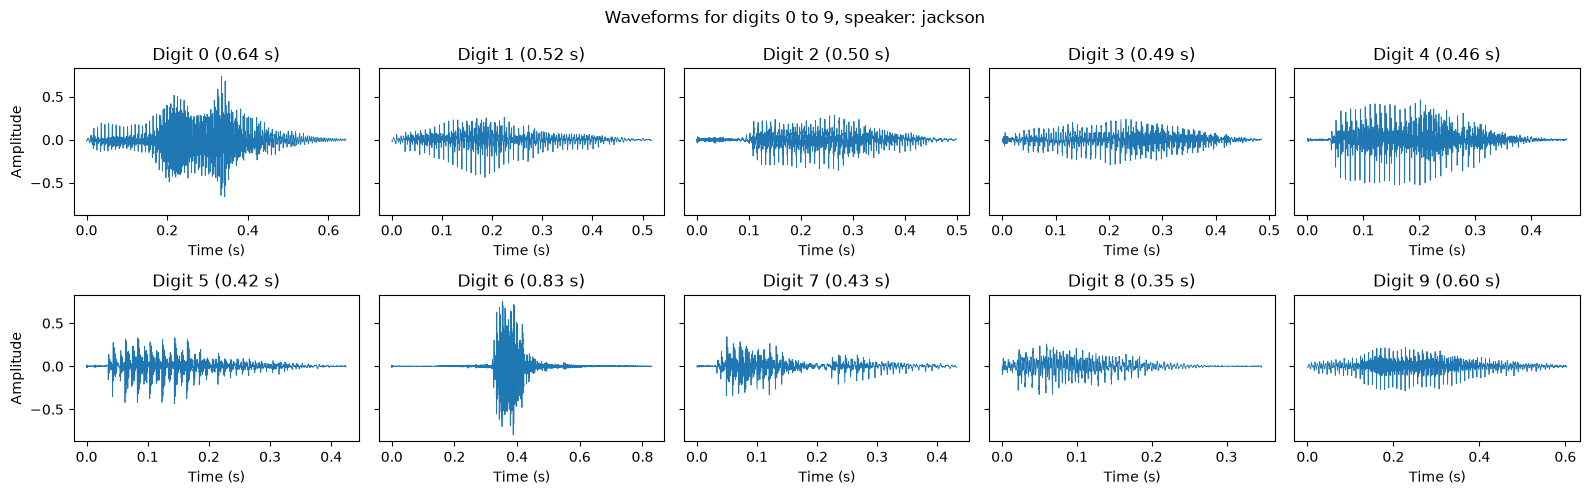

In [12]:
speaker = "jackson"
fig, axes = plt.subplots(2, 5, figsize=(16, 5), sharey=True)

for digit, ax in zip(range(10), axes.flat):
    path = df.loc[(df["speaker"] == speaker) & (df["digit"] == digit), "path"].iloc[0]
    y, sr = librosa.load(path, sr=None)
    t = np.arange(len(y)) / sr

    ax.plot(t, y, linewidth=0.6)
    ax.set_title(f"Digit {digit} ({len(y) / sr:.2f} s)")
    ax.set_xlabel("Time (s)")

axes[0, 0].set_ylabel("Amplitude")
axes[1, 0].set_ylabel("Amplitude")
fig.suptitle(f"Waveforms for digits 0 to 9, speaker: {speaker}")
plt.tight_layout()
plt.show()

### Spectogram per digit

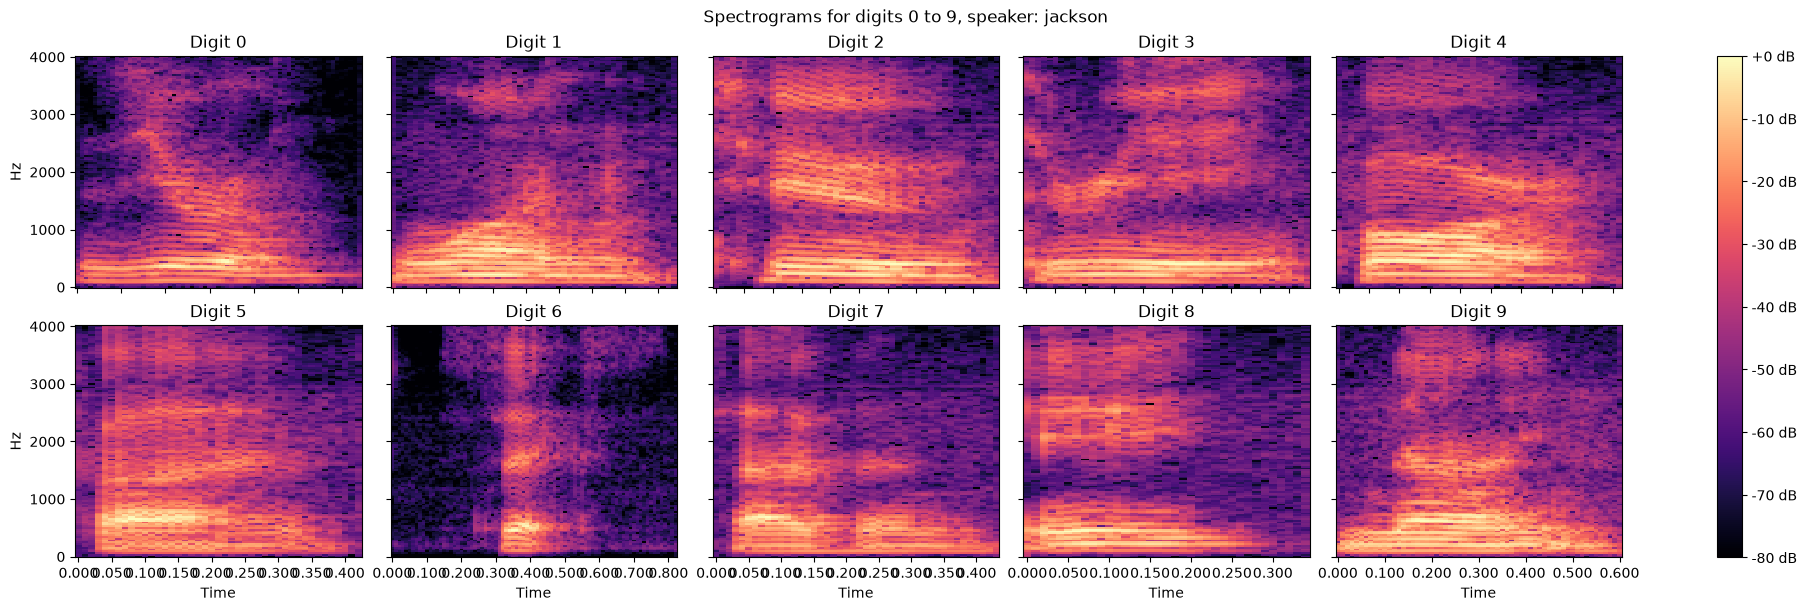

(129, 61)


In [13]:
speaker = "jackson"
n_fft, hop_length = 256, 80

fig, axes = plt.subplots(2, 5, figsize=(18, 6), sharey=True, constrained_layout=True)

for digit, ax in zip(range(10), axes.flat):
    path = df.loc[(df["speaker"] == speaker) & (df["digit"] == digit), "path"].iloc[0]
    y, sr = librosa.load(path, sr=None)

    D = librosa.stft(y, n_fft=n_fft, hop_length=hop_length)   # complex, shape (n_fft/2 + 1, n_frames)
    S_db = librosa.amplitude_to_db(np.abs(D), ref=np.max)     # magnitude in dB, max = 0 dB

    img = librosa.display.specshow(S_db, sr=sr, hop_length=hop_length,
                                   x_axis="time", y_axis="hz", ax=ax, vmin=-80, vmax=0)
    ax.set_title(f"Digit {digit}")
    ax.label_outer()

fig.colorbar(img, ax=axes, format="%+2.0f dB")
fig.suptitle(f"Spectrograms for digits 0 to 9, speaker: {speaker}")
plt.show()

print(D.shape)   # check: 129 frequency bins = n_fft/2 + 1

### Histogram of durations, overall and per speaker

count    2000.000000
mean        0.402169
std         0.133673
min         0.143500
25%         0.316375
50%         0.389875
75%         0.466062
max         2.282750
Name: duration [s], dtype: float64
          count   mean    std    min    25%    50%    75%    max
speaker                                                         
jackson   500.0  0.516  0.107  0.344  0.436  0.492  0.581  0.880
nicolas   500.0  0.349  0.080  0.144  0.300  0.349  0.403  0.574
theo      500.0  0.389  0.168  0.161  0.283  0.370  0.450  2.283
yweweler  500.0  0.354  0.083  0.144  0.299  0.347  0.407  0.684


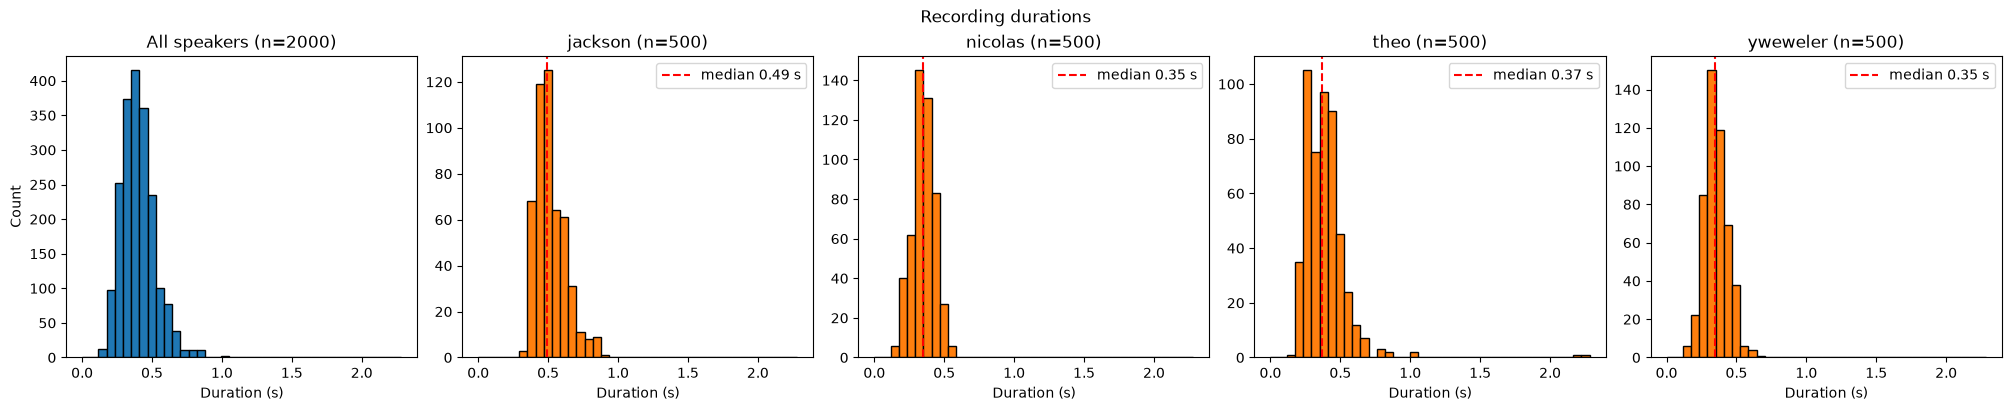

In [14]:
print(df["duration [s]"].describe())
print(df.groupby("speaker")["duration [s]"].describe().round(3))

speakers = sorted(df["speaker"].unique())
bins = np.linspace(0, df["duration [s]"].max(), 40)   # same bins everywhere, so panels are comparable

fig, axes = plt.subplots(1, 1 + len(speakers), figsize=(20, 4), sharex=True, constrained_layout=True)

axes[0].hist(df["duration [s]"], bins=bins, edgecolor="black")
axes[0].set_title(f"All speakers (n={len(df)})")
axes[0].set_ylabel("Count")

for ax, spk in zip(axes[1:], speakers):
    d = df.loc[df["speaker"] == spk, "duration [s]"]
    ax.hist(d, bins=bins, edgecolor="black", color="tab:orange")
    ax.axvline(d.median(), color="red", linestyle="--", label=f"median {d.median():.2f} s")
    ax.set_title(f"{spk} (n={len(d)})")
    ax.legend()

for ax in axes:
    ax.set_xlabel("Duration (s)")

fig.suptitle("Recording durations")
plt.show()

### Conclusions: recording durations

- **Short recordings overall.** The median duration is 0.39 s and the interquartile range is 0.32 s to 0.47 s, so half of all recordings fall within a window of about 0.15 s. The shortest recording lasts 0.14 s.
- **Right-skewed distribution.** Most recordings are under 0.6 s, with a thin tail towards 1 s. Every speaker except Theo stays below 0.9 s.
- **One clear outlier.** A single recording by Theo lasts 2.28 s, roughly six times the median. Since a spoken digit takes well under a second, this is most likely long silence or noise around the word, not a slow pronunciation. It also explains Theo's larger standard deviation (0.168 s compared with 0.08 to 0.11 s for the others).
- **Speaker differences.** Jackson is systematically slower: his median is 0.49 s, compared with 0.35 s to 0.37 s for Nicolas, Theo and Yweweler, and his whole distribution is shifted to the right. The other three speakers have very similar distributions.

**Implications for preprocessing**

- A fixed length of $L = 1$ s ($8000$ samples at $8$ kHz) keeps every recording from Jackson, Nicolas and Yweweler complete and truncates only a handful of Theo's recordings, including the outlier. Most clips will be zero-padded rather than truncated.
- Because most clips are much shorter than 1 s, a shorter $L$ (about 0.8 s) may be enough once silence is trimmed. The choice will be revisited after the silence analysis.
- Duration carries speaker information (Jackson is longer). After padding, the amount of trailing silence can act as a speaker cue, so the model could partly learn the speaker instead of the digit. This is another reason to report results on the speaker-based split.

In [15]:
# checking potential outlier
outlier = df.loc[df["duration [s]"].idxmax()]
print(outlier)
Audio(outlier["path"])

path            data/FSDD/FSDD/recordings/9_theo_16.wav
digit                                                 9
speaker                                            theo
sample_rate                                        8000
n_samples                                         18262
duration [s]                                    2.28275
Name: 1908, dtype: object


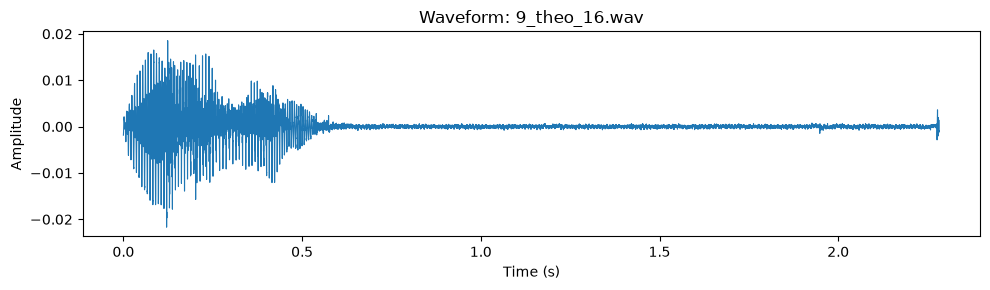

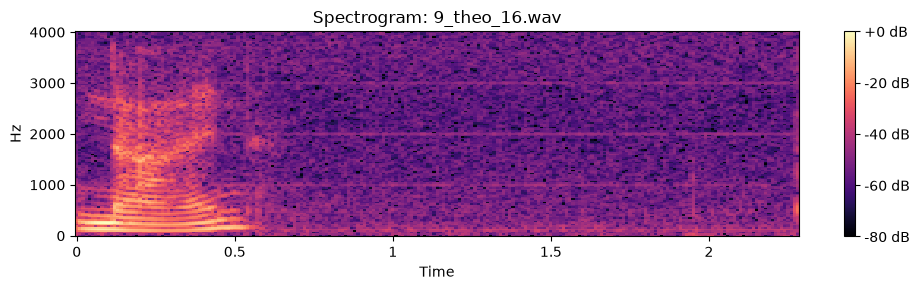

In [16]:
outlier = df.loc[df["duration [s]"].idxmax()]
y, sr = librosa.load(outlier["path"], sr=None)

# Waveform
t = np.arange(len(y)) / sr

plt.figure(figsize=(10, 3))
plt.plot(t, y, linewidth=0.8)
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.title(f"Waveform: {outlier['path'].split('/')[-1]}")
plt.tight_layout()
plt.show()

# Spectrogram
S_db = librosa.amplitude_to_db(np.abs(librosa.stft(y, n_fft=256, hop_length=80)), ref=np.max)

plt.figure(figsize=(10, 3))
librosa.display.specshow(S_db, sr=sr, hop_length=80, x_axis="time", y_axis="hz")
plt.colorbar(format="%+2.0f dB")
plt.title(f"Spectrogram: {outlier['path'].split('/')[-1]}")
plt.tight_layout()
plt.show()

## Preprocessing

### Settings
All preprocessing parameters are defined once here, so they are easy to change later.

In [17]:
SEED = 42
SR = 8000       # sample rate of FSDD
TOP_DB = 30     # silence threshold for trimming
N_FFT = 512     # window size for the spectrogram
HOP = 128       # step between windows
N_MELS = 64     # number of frequency bands
np.random.seed(SEED)

### Trimming silence and choosing a fixed length
Most recordings have quiet parts at the start and end. Trimming removes them, so every clip starts where the digit starts.

A neural network needs every input to be the same size, but the clips have different lengths. We choose one length that is long enough for 95% of the clips.

Fixed length: 5000 samples = 0.625 s
Share of clips cut short: 0.028


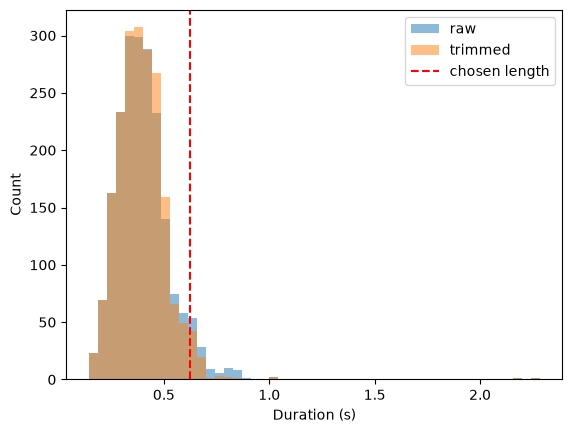

In [18]:
waves = []
for p in df["path"]:
    y, _ = librosa.load(p, sr=None)
    y_trim, _ = librosa.effects.trim(y, top_db=TOP_DB)
    waves.append(y_trim)

df["n_trimmed"] = [len(w) for w in waves]

N_SAMPLES = int(np.ceil(df["n_trimmed"].quantile(0.95) / 1000) * 1000)
print("Fixed length:", N_SAMPLES, "samples =", N_SAMPLES / SR, "s")
print("Share of clips cut short:", round((df["n_trimmed"] > N_SAMPLES).mean(), 3))

plt.hist(df["n_samples"] / SR, bins=50, alpha=0.5, label="raw")
plt.hist(df["n_trimmed"] / SR, bins=50, alpha=0.5, label="trimmed")
plt.axvline(N_SAMPLES / SR, color="red", linestyle="--", label="chosen length")
plt.xlabel("Duration (s)"); plt.ylabel("Count"); plt.legend(); plt.show()

### Fixed length and log-mel spectrograms
- **Fixed length:** short clips get silence (zeros) added at the end, and long clips are cut.
- **Spectrogram:** shows which frequencies are present at each moment in time. This turns each sound into a picture.
- **Mel scale:** groups the frequencies the way human hearing does, into 64 bands.
- **Log (decibels):** compresses very loud and very quiet values onto a similar scale, like our ears do.

Result: each clip becomes a 64 ﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿ time image, so we can use a CNN just like for MRI or cloud images.

### Example spectrograms
One spectrogram per digit. Brighter colours mean more energy. Each digit has its own pattern, and that pattern is what the model will learn to recognise.

In [19]:
def log_mel(y):
    S = librosa.feature.melspectrogram(y=y, sr=SR, n_fft=N_FFT, hop_length=HOP,
                                       n_mels=N_MELS, fmax=SR // 2)
    return librosa.power_to_db(S, ref=np.max)

X = np.stack([log_mel(librosa.util.fix_length(w, size=N_SAMPLES)) for w in waves]).astype(np.float32)
y = df["digit"].to_numpy()
print("X shape:", X.shape, "| y shape:", y.shape)

X shape: (2000, 64, 40) | y shape: (2000,)


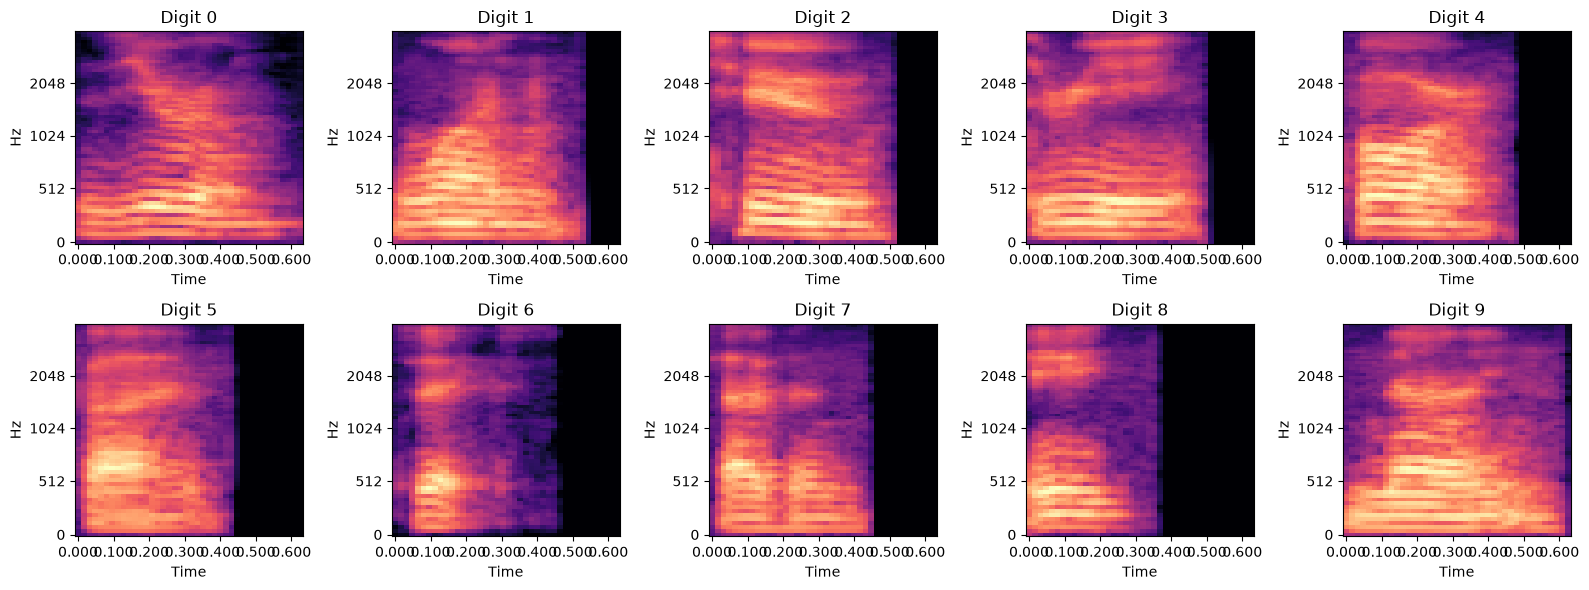

In [20]:
fig, axes = plt.subplots(2, 5, figsize=(16, 6))
for d, ax in enumerate(axes.flat):
    i = np.where(y == d)[0][0]
    librosa.display.specshow(X[i], sr=SR, hop_length=HOP, x_axis="time",
                             y_axis="mel", fmax=SR // 2, ax=ax)
    ax.set_title(f"Digit {d}")
plt.tight_layout(); plt.show()

## Normalization
Each frequency band is rescaled to mean 0 and standard deviation 1:

$$\tilde{x} = \frac{x - \mu}{\sigma}$$

This helps the network train faster. The mean and standard deviation are computed from the training set only, so no information from the test set leaks into training.

In [21]:
idx = np.arange(len(df))
train_idx, temp_idx = train_test_split(idx, test_size=0.30, stratify=y, random_state=SEED)
val_idx, test_idx = train_test_split(temp_idx, test_size=0.50, stratify=y[temp_idx], random_state=SEED)

print(len(train_idx), len(val_idx), len(test_idx))

1400 300 300


In [22]:
mu = X[train_idx].mean(axis=(0, 2), keepdims=True)
sd = X[train_idx].std(axis=(0, 2), keepdims=True) + 1e-8

X_norm = (X - mu) / sd

print(X_norm.shape)

(2000, 64, 40)


## Train test split

### Note on the split
All 4 speakers appear in train, validation and test, so the model is evaluated on voices it has already heard. The accuracy is therefore likely optimistic, and performance on new speakers may be lower.


In [23]:
X_train, y_train = X_norm[train_idx], y[train_idx]
X_val, y_val = X_norm[val_idx], y[val_idx]
X_test, y_test = X_norm[test_idx], y[test_idx]

print(X_train.shape, X_val.shape, X_test.shape)

(1400, 64, 40) (300, 64, 40) (300, 64, 40)


### Check
Every digit appears equally often in each set, so no digit is over- or under-represented.

In [24]:
print("Train per digit:", np.bincount(y_train))
print("Val per digit:  ", np.bincount(y_val))
print("Test per digit: ", np.bincount(y_test))

Train per digit: [140 140 140 140 140 140 140 140 140 140]
Val per digit:   [30 30 30 30 30 30 30 30 30 30]
Test per digit:  [30 30 30 30 30 30 30 30 30 30]


## Next steps
1. **Baseline model:** summarise each clip with simple sound features (MFCC averages) and train a classic classifier, such as logistic regression or SVM. This gives a reference score to beat.
2. **PyTorch data:** convert the train, validation and test sets into PyTorch tensors and DataLoaders.
3. **CNN model:** build a small convolutional neural network that classifies the spectrogram images into the 10 digits.
4. **Training:** train the CNN, track training and validation accuracy, and keep the best model.
5. **Evaluation:** measure the final accuracy on the test set, show the confusion matrix, and compare the CNN with the baseline.

In [25]:
N_MFCC = 13

def mfcc_stats(w):
    m = librosa.feature.mfcc(y=w, sr=SR, n_mfcc=N_MFCC, n_fft=N_FFT,
                             hop_length=HOP, n_mels=N_MELS, fmax=SR // 2)
    return np.concatenate([m.mean(axis=1), m.std(axis=1)])

F = np.stack([mfcc_stats(w) for w in waves]).astype(np.float32)
print("F shape:", F.shape)   # expect (2000, 26)

F shape: (2000, 26)


### Baseline features: MFCC mean and standard deviation
MFCCs summarise the shape of the spectrum in each short frame. For each of the 13 coefficients, we take its average and its spread over the whole clip. This gives one vector of 26 numbers per recording, which is what a classic classifier needs.

In [26]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

F_tr, F_va, F_te = F[train_idx], F[val_idx], F[test_idx]
y_tr, y_va, y_te = y[train_idx], y[val_idx], y[test_idx]

results = {}
for C in [0.01, 0.1, 1, 10, 100]:
    clf = make_pipeline(StandardScaler(),
                        LogisticRegression(C=C, max_iter=2000, random_state=SEED))
    clf.fit(F_tr, y_tr)
    results[C] = (accuracy_score(y_tr, clf.predict(F_tr)),
                  accuracy_score(y_va, clf.predict(F_va)))
    print(f"C={C:<6} train={results[C][0]:.3f}  val={results[C][1]:.3f}")

best_C = max(results, key=lambda c: results[c][1])
print("Best C:", best_C)

C=0.01   train=0.910  val=0.897
C=0.1    train=0.961  val=0.950
C=1      train=0.984  val=0.960
C=10     train=0.994  val=0.950
C=100    train=0.997  val=0.937
Best C: 1


### Logistic regression and choosing C
The scaler and the classifier are combined in a pipeline, so the mean and standard deviation are learned from the training set only (no leakage).
`C` controls regularisation: a small `C` gives a simpler model, a large `C` gives a more flexible one. We choose `C` using the validation set, not the test set.

Test accuracy: 0.947
              precision    recall  f1-score   support

           0      1.000     0.933     0.966        30
           1      0.963     0.867     0.912        30
           2      0.882     1.000     0.938        30
           3      0.935     0.967     0.951        30
           4      1.000     0.933     0.966        30
           5      0.938     1.000     0.968        30
           6      0.963     0.867     0.912        30
           7      0.967     0.967     0.967        30
           8      0.909     1.000     0.952        30
           9      0.933     0.933     0.933        30

    accuracy                          0.947       300
   macro avg      0.949     0.947     0.946       300
weighted avg      0.949     0.947     0.946       300



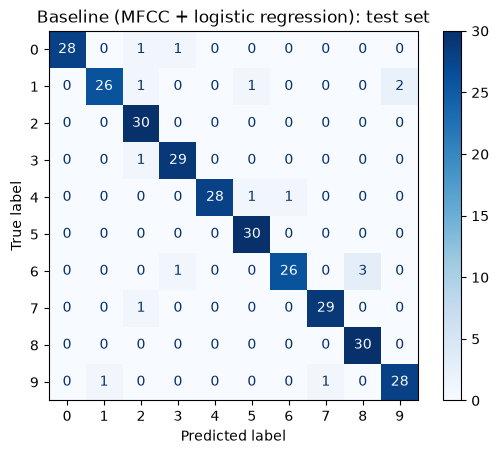

In [27]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

baseline = make_pipeline(StandardScaler(),
                         LogisticRegression(C=best_C, max_iter=2000, random_state=SEED))
baseline.fit(F_tr, y_tr)
y_pred = baseline.predict(F_te)

print("Test accuracy:", round(accuracy_score(y_te, y_pred), 3))
print(classification_report(y_te, y_pred, digits=3))
ConfusionMatrixDisplay.from_predictions(y_te, y_pred, cmap="Blues")
plt.title("Baseline (MFCC + logistic regression): test set")
plt.show()

### Baseline results on the test set
The test set is used only once, after choosing `C`. This accuracy is the number the CNN should beat.

### Baseline summary: MFCC statistics + logistic regression

**Overall:** the baseline reaches **94.7% test accuracy** (284 of 300 clips correct, 16 errors). Macro and weighted F1 are both 0.946, which is expected because the test set is balanced (30 clips per digit).

**Per digit:**
- **Easiest:** digits 2, 5 and 8 have perfect recall (every clip of these digits was recognised).
- **Hardest:** digits 1 and 6 have the lowest recall (0.867, i.e. 4 of 30 clips missed each).
- **Most over-predicted:** digit 2 has the lowest precision (0.882): 4 clips of other digits were wrongly labelled as 2. Digit 8 is similar (precision 0.909, 3 false positives).

## PyTorch dataset

In [28]:
class SpectrogramDataset(Dataset):
    """Wraps log-mel spectrograms and labels as PyTorch tensors."""

    def __init__(self, X, y):
        self.X = torch.from_numpy(X).unsqueeze(1)   # (N, 1, n_mels, n_frames) - add channel dim for CNN
        self.y = torch.from_numpy(y).long()

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]


BATCH_SIZE = 32

train_ds = SpectrogramDataset(X_train, y_train)
val_ds = SpectrogramDataset(X_val, y_val)
test_ds = SpectrogramDataset(X_test, y_test)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False)

print(f"Train: {len(train_ds)} samples, {len(train_loader)} batches")
print(f"Val:   {len(val_ds)} samples, {len(val_loader)} batches")
print(f"Test:  {len(test_ds)} samples, {len(test_loader)} batches")

Train: 1400 samples, 44 batches
Val:   300 samples, 10 batches
Test:  300 samples, 10 batches


In [29]:
xb, yb = next(iter(train_loader))
print("Batch X shape:", xb.shape, "| dtype:", xb.dtype)
print("Batch y shape:", yb.shape, "| dtype:", yb.dtype)

Batch X shape: torch.Size([32, 1, 64, 40]) | dtype: torch.float32
Batch y shape: torch.Size([32]) | dtype: torch.int64
